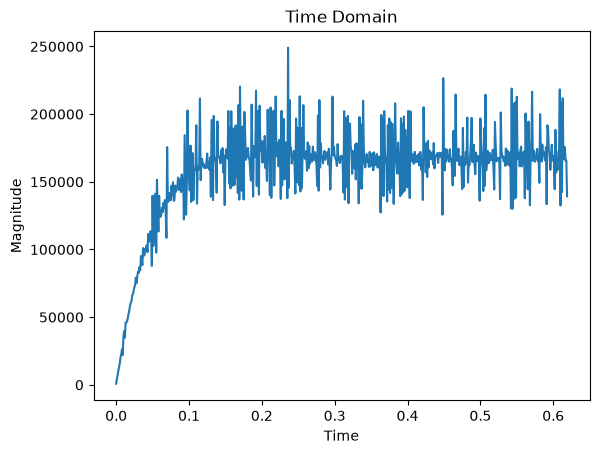

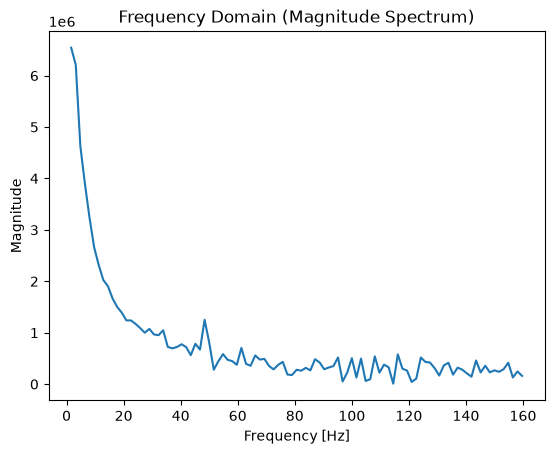

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import arslabrobotics as ar

data = np.loadtxt("motor_data.txt")
(rows, _) = data.shape

delta_t = 0.001  # Sampling interval

# get the signal
signal = data[:,1]

# Compute FFT
fft_values = np.fft.fft(signal)
N = len(signal)

# Compute frequency bins
freq = np.fft.fftfreq(N, delta_t)

# Take the magnitude (absolute value) of the FFT
magnitude = np.abs(fft_values)

n_samples = N
plt.plot(np.arange(n_samples) * delta_t, signal[:n_samples])
plt.title('Time Domain')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.show()


n_samples = 100#N//2
plt.plot(freq[1:n_samples], magnitude[1:n_samples])
plt.title('Frequency Domain (Magnitude Spectrum)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()


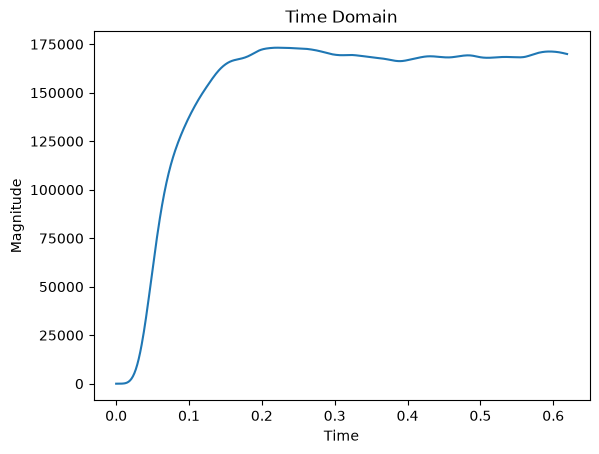

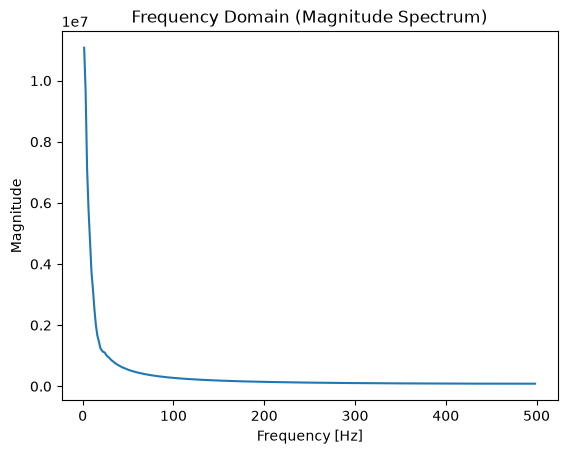

In [14]:

# apply filter
low_pass = ar.filters.Chebysev2Filter(5, 'lowpass', 100, 100, 1.0/delta_t)

filtered_signal = []
for v in signal:
    filtered_signal.append(low_pass.evaluate(v))

# Compute FFT
fft_values = np.fft.fft(filtered_signal)
N = len(filtered_signal)

# Compute frequency bins
freq = np.fft.fftfreq(N, delta_t)

# Take the magnitude (absolute value) of the FFT
magnitude = np.abs(fft_values)

n_samples = N
plt.plot(np.arange(n_samples) * delta_t, filtered_signal[:n_samples])
plt.title('Time Domain')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.show()

n_samples = N//2
plt.plot(freq[1:n_samples], magnitude[1:n_samples])
plt.title('Frequency Domain (Magnitude Spectrum)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()